In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
plt.rcParams["text.usetex"] = True
plt.rcParams["font.family"] = "Times New Roman"
#plt.rcParams["mathtext.fontset"] = "custom"
#plt.rcParams["mathtext.rm"] = "Times New Roman"

import matplotlib.colors as mcolors
import matplotlib as mpl

white_blue_red = mcolors.LinearSegmentedColormap.from_list(
    "white_blue_red",
    [(0, "white"), (0.5, "blue"), (1, "red")]
)

import matplotlib.cm as cm
colors = cm.viridis(np.linspace(0,1,14))

In [2]:
def readlmpEne(filename):
    output = []
    with open(filename,'r') as f:
        while True:
            line = f.readline()
            if not line:
                break
            else:
                if 'Step Temp PotEng KinEng E_vdwl E_coul E_bond E_angle' in line:
                    for i in range(101):
                        line = f.readline()
                        output.append([float(x) for x in line.split()])
                        if 'Loop time of' in line:
                            break
    return np.array(output)

In [3]:
f_lmpene = 'log.lammps'
d_lmpene = readlmpEne(f_lmpene)

In [4]:
def readData(filename):
    output = []
    with open(filename,'r') as f:
        while True:
            line = f.readline()
            if not line:
                break
            else:
                if 'Step ' not in line:
                    output = [float(x) for x in line.split()]

    return output

In [5]:
enetest = []
for i in range(0,10000001,100000):
    f_tmp = 'log.{}'.format(i)
    d_tmp = readData(f_tmp)
    enetest.append(d_tmp)

enetest = np.array(enetest)

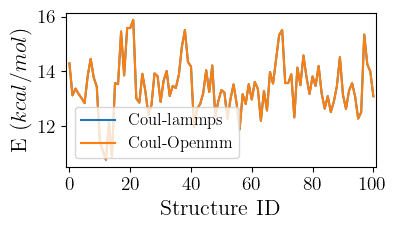

In [6]:
fig, ax = plt.subplots(figsize=(4,2))

ax.plot(d_lmpene[:,0]/10**5, d_lmpene[:,5], label='Coul-lammps')
ax.plot(d_lmpene[:,0]/10**5, enetest[:,-1], label='Coul-Openmm')
ax.legend(fontsize=12)

ax.set_xlabel(r'Structure ID',fontsize=16)
ax.set_ylabel(r'E ($kcal/mol$)',fontsize=16)

ax.set_xlim(-1,101)

ax.xaxis.set_ticks(np.arange(0,100.1,20))
#ax.yaxis.set_ticks(np.arange(0,100.1,25))

ax.xaxis.set_tick_params(labelsize=14)
ax.yaxis.set_tick_params(labelsize=14)

plt.savefig('figures/ene_coul.png', dpi=1000, bbox_inches='tight')

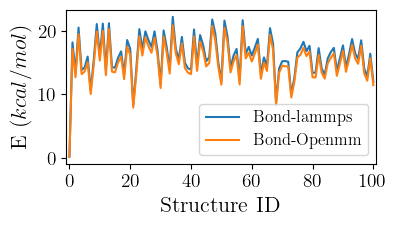

In [7]:
fig, ax = plt.subplots(figsize=(4,2))

ax.plot(d_lmpene[:,0]/10**5, d_lmpene[:,6], label='Bond-lammps')
ax.plot(d_lmpene[:,0]/10**5, enetest[:,1], label='Bond-Openmm')
ax.legend(fontsize=12)

ax.set_xlabel(r'Structure ID',fontsize=16)
ax.set_ylabel(r'E ($kcal/mol$)',fontsize=16)

ax.set_xlim(-1,101)

ax.xaxis.set_ticks(np.arange(0,100.1,20))
#ax.yaxis.set_ticks(np.arange(0,100.1,25))

ax.xaxis.set_tick_params(labelsize=14)
ax.yaxis.set_tick_params(labelsize=14)

plt.savefig('figures/ene_bond.png', dpi=1000, bbox_inches='tight')

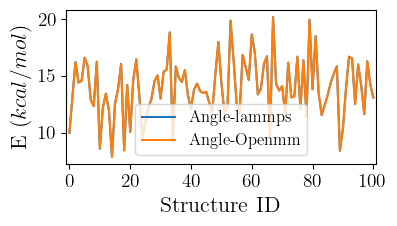

In [8]:
fig, ax = plt.subplots(figsize=(4,2))

ax.plot(d_lmpene[:,0]/10**5, d_lmpene[:,-1], label='Angle-lammps')
ax.plot(d_lmpene[:,0]/10**5, enetest[:,2], label='Angle-Openmm')
ax.legend(fontsize=12)

ax.set_xlabel(r'Structure ID',fontsize=16)
ax.set_ylabel(r'E ($kcal/mol$)',fontsize=16)

ax.set_xlim(-1,101)

ax.xaxis.set_ticks(np.arange(0,100.1,20))
#ax.yaxis.set_ticks(np.arange(0,100.1,25))

ax.xaxis.set_tick_params(labelsize=14)
ax.yaxis.set_tick_params(labelsize=14)

plt.savefig('figures/ene_angle.png', dpi=1000, bbox_inches='tight')

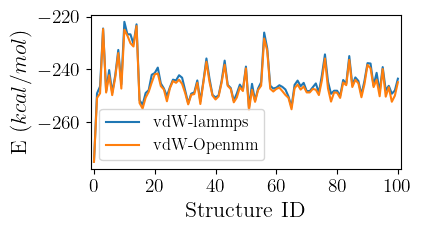

In [9]:
fig, ax = plt.subplots(figsize=(4,2))

ax.plot(d_lmpene[:,0]/10**5, d_lmpene[:,4], label='vdW-lammps')
ax.plot(d_lmpene[:,0]/10**5, enetest[:,3]+enetest[:,4]+enetest[:,5], label='vdW-Openmm')
#ax.scatter(d_lmpene[:,0]/10**5, enetest[:,3]+enetest[:,4]+enetest[:,5], label='vdW-Openmm')
ax.legend(fontsize=12)

ax.set_xlabel(r'Structure ID',fontsize=16)
ax.set_ylabel(r'E ($kcal/mol$)',fontsize=16)

ax.set_xlim(-1,101)

ax.xaxis.set_ticks(np.arange(0,100.1,20))
#ax.yaxis.set_ticks(np.arange(0,100.1,25))

ax.xaxis.set_tick_params(labelsize=14)
ax.yaxis.set_tick_params(labelsize=14)

plt.savefig('figures/ene_vdW.png', dpi=1000, bbox_inches='tight')